# 🛠️ Feature Engineering: Transformation, Encoding & Selection

---

## 1. Overview

> *"Coming up with features is difficult, time-consuming, requires expert knowledge. 'Applied machine learning' is basically feature engineering."* — Andrew Ng

While modern algorithms are powerful function approximators, their performance is strictly bounded by the information geometry of the input features. Raw tabular data in the wild is messy: heavily skewed distributions, extreme outliers, missing entries, high-cardinality identifiers, and uninformative timestamps degrade model convergence, stability, and predictive accuracy.

This notebook covers the four core pillars of feature engineering:
- **Missing Data Diagnosis & Imputation**: Understanding missingness mechanisms (MCAR, MAR, MNAR) and contrasting Univariate Imputation (`SimpleImputer`) with Multivariate Imputation (`KNNImputer`, `IterativeImputer` / MICE) and Missingness Indicators.
- **Categorical Feature Encoding**: The curse of cardinality in One-Hot Encoding, Ordinal Encoding, Frequency Encoding, and Bayesian-smoothed Target Encoding.
- **Numerical Transformations & Scaling**: Skewness reduction using Yeo-Johnson Power Transformations, Quantile Transformations to Gaussian distributions, and outlier-resilient scaling (`RobustScaler`).
- **Feature Construction**: Generating domain interaction ratios, polynomial features, and cyclical periodic encodings ($\sin / \cos$) for date/time attributes.
- **Feature Selection Taxonomy**: Filter methods (Mutual Information, ANOVA F-test), Wrapper methods (Recursive Feature Elimination - RFE), and Embedded methods (L1 Lasso, Tree Importances, Permutation Importance).

We will construct an e-commerce customer transaction dataset and demonstrate measurable downstream model gains at each stage of engineering.

## 2. Learning Objectives

By the end of this notebook, you will be able to:

- Diagnose missing data mechanisms (MCAR, MAR, MNAR) and apply univariate and multivariate imputation.
- Prevent categorical cardinality explosion using target encoding with Bayesian smoothing and frequency encoding.
- Normalize skewed, fat-tailed feature distributions using Yeo-Johnson power transformations and Quantile transforms.
- Encode cyclical temporal features (hours, days, months) into continuous periodic representations using trigonometric functions.
- Classify and apply the three families of feature selection: Filter methods, Wrapper methods (RFE), and Embedded methods ($L_1$ penalty, Tree importance).
- Implement a Boruta-style shadow feature selection algorithm to statistically separate signal from noise.
- Quantify empirical accuracy and ROC-AUC gains resulting strictly from feature engineering.

## 3. Imports

We import numerical libraries, plotting utilities, and scikit-learn preprocessing, imputation, and feature selection modules.

In [1]:
import time
from typing import Dict, List, Tuple, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.impute import SimpleImputer, KNNImputer, MissingIndicator
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import (
    StandardScaler,
    RobustScaler,
    MinMaxScaler,
    PowerTransformer,
    QuantileTransformer,
    OneHotEncoder,
    OrdinalEncoder,
    TargetEncoder,
    PolynomialFeatures
)
from sklearn.feature_selection import (
    mutual_info_classif,
    f_classif,
    SelectKBest,
    RFE,
    SelectFromModel
)
from sklearn.linear_model import LogisticRegression, LassoCV
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, accuracy_score

print(f"NumPy version:        {np.__version__}")
print(f"Pandas version:       {pd.__version__}")
print(f"scikit-learn version: {sklearn.__version__}")

NumPy version:        2.4.6
Pandas version:       3.1.1
scikit-learn version: 1.9.1


## 4. Configuration

We configure plotting aesthetics, pandas output precision, and global seeds.

In [2]:
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.rcParams["figure.figsize"] = (10, 5)
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 25)

## 5. Theory & Key Concepts

### 5.1 Missing Data Mechanisms & Imputation

Missing data falls into three Rubin taxonomy classes:
1. **MCAR (Missing Completely at Random)**: The probability of missingness is completely independent of both observed and unobserved data:
   $$P(M | Y_{\text{obs}}, Y_{\text{mis}}) = P(M)$$
2. **MAR (Missing at Random)**: Missingness depends systematically on observed variables, but not on the missing value itself:
   $$P(M | Y_{\text{obs}}, Y_{\text{mis}}) = P(M | Y_{\text{obs}})$$
3. **MNAR (Missing Not at Random)**: Missingness depends directly on the unobserved value itself (e.g., high earners refusing to disclose income):
   $$P(M | Y_{\text{obs}}, Y_{\text{mis}}) \neq P(M | Y_{\text{obs}})$$

#### Imputation Strategies:
- **Simple Imputer**: Imputes univariate summary statistics (Mean, Median, Most Frequent). Fast, but collapses feature variance and ignores correlation structure.
- **Multivariate Imputation by Chained Equations (MICE / `IterativeImputer`)**: Models each feature with missing values as a function of other features in a round-robin iterative regression loop. Preserves multivariate relationships.
- **KNN Imputer**: Replaces missing values using the weighted Euclidean average of the $K$ nearest complete neighbors.
- **Missingness Indicator**: Appends a binary indicator column ($I_m \in \{0, 1\}$) signaling that data was originally missing. Critical for MNAR signals.

### 5.2 Categorical Encodings & Bayesian Target Smoothing

#### One-Hot Encoding vs. The Dimensionality Curse
One-hot encoding maps a categorical feature with $C$ levels to $C$ binary indicator columns. For high-cardinality features ($C > 50$), this causes exponential sparsity and memory bloat, while forcing tree models to make unbalanced splits.

#### Bayesian Smoothed Target Encoding
Target encoding replaces each categorical level $c$ with the expected target value:

$$S_c = \lambda(n_c) \cdot \bar{y}_c + (1 - \lambda(n_c)) \cdot \bar{y}_{\text{global}}$$

Where $\lambda(n_c)$ is an empirical Bayes smoothing weight:

$$\lambda(n_c) = \frac{n_c}{n_c + m}$$
- $n_c$: Number of training samples observed with category $c$.
- $\bar{y}_c$: Empirical target mean for category $c$.
- $\bar{y}_{\text{global}}$: Global target mean across the entire dataset.
- $m$: Smoothing parameter (prior pseudo-counts). When $n_c$ is small, $S_c \to \bar{y}_{\text{global}}$, preventing catastrophic overfitting on rare levels.

### 5.3 Numerical Power Transformations & Robust Scaling

Many linear, distance-based, and gradient algorithms assume approximately Gaussian feature distributions. Fat-tailed, right-skewed data degrades convergence.

#### Yeo-Johnson Transformation
The Yeo-Johnson power transformation extends the Box-Cox transform to support zero and negative values:

$$\psi(\lambda, x) = \begin{cases} 
\frac{(x + 1)^\lambda - 1}{\lambda} & \text{if } \lambda \neq 0, x \ge 0 \\ 
\ln(x + 1) & \text{if } \lambda = 0, x \ge 0 \\ 
-\frac{(-x + 1)^{2 - \lambda} - 1}{2 - \lambda} & \text{if } \lambda \neq 2, x < 0 \\ 
-\ln(-x + 1) & \text{if } \lambda = 2, x < 0 
\end{cases}$$

Optimal parameter $\hat{\lambda}$ is estimated via Maximum Likelihood Estimation (MLE).

#### Robust Scaling vs. Standard Scaling
Standard scaling uses mean and standard deviation: $z = \frac{x - \mu}{\sigma}$. A few extreme outliers inflate $\mu$ and $\sigma$, compressing the inlier range.
`RobustScaler` uses median and Interquartile Range (IQR):

$$x_{\text{robust}} = \frac{x - \text{median}(x)}{\text{IQR}(x)} = \frac{x - Q_2}{Q_3 - Q_1}$$

### 5.4 Cyclical Encoding of Temporal Features

Date/time attributes (hour of day $\in [0, 23]$, month $\in [1, 12]$) are inherently cyclical: hour 23:59 is only 2 minutes away from hour 00:01. However, treating time as a linear integer implies that 23 and 0 are maximally distant ($|23 - 0| = 23$).

To preserve cyclical topology, we project linear time $t$ onto a 2D unit circle using trigonometric sine and cosine:

$$x_{\sin} = \sin\left(\frac{2\pi t}{T}\right), \qquad x_{\cos} = \cos\left(\frac{2\pi t}{T}\right)$$

Where $T$ is the cycle period ($T=24$ for hours, $T=7$ for days of week, $T=12$ for months).

### 5.5 Taxonomy of Feature Selection

| Family | Mechanism | Pros | Cons | Scikit-Learn Tools |
|---|---|---|---|---|
| **Filter Methods** | Evaluates statistical correlation/mutual information between feature $X_j$ and target $y$ independently. | Extremely fast, model-agnostic, scales to millions of features. | Ignores feature interactions; may retain redundant correlated features. | `mutual_info_classif`, `f_classif`, `SelectKBest` |
| **Wrapper Methods** | Uses a predictive model to evaluate combinations of features iteratively. | Accounts for feature interactions; optimized directly for estimator performance. | Computationally expensive; prone to overfitting search folds. | `RFE`, `RFECV`, Sequential Feature Selector (`SFS`) |
| **Embedded Methods** | Feature selection occurs internally during model optimization. | Balances computational efficiency and interaction awareness. | Tied to specific algorithm families ($L_1$ regularized linear models, tree ensembles). | `LassoCV`, `SelectFromModel`, `RandomForestClassifier.feature_importances_` |

## 6. Implementation

### 6.1 Synthesizing an E-Commerce Customer Analytics Dataset

We generate a realistic tabular dataset with 12,000 customer sessions featuring:
- Heavily skewed monetary features (`total_spend_annual`, `cart_value`)
- Missing values (MCAR and MAR)
- High-cardinality categories (`merchant_category`, `customer_city`)
- Temporal attributes (`purchase_hour`)
- Pure noise features (to evaluate feature selection)
- Binary Target: `high_value_customer` (1 = high lifetime value, 0 = standard)

In [3]:
def generate_ecommerce_dataset(n_samples: int = 12000, random_state: int = RANDOM_SEED) -> pd.DataFrame:
    """Generates realistic e-commerce customer transaction dataset with varied feature properties."""
    rng = np.random.default_rng(random_state)
    
    # Skewed monetary features (lognormal)
    annual_spend = rng.lognormal(mean=6.5, sigma=1.2, size=n_samples) # Heavy right tail
    cart_value = rng.lognormal(mean=4.2, sigma=0.9, size=n_samples)
    
    # Behavior metrics
    session_duration_min = rng.gamma(shape=2.5, scale=8.0, size=n_samples)
    pages_viewed = rng.poisson(lam=6.0, size=n_samples) + 1
    return_rate = rng.beta(a=1.5, b=8.0, size=n_samples)
    
    # Categoricals
    categories = ["Electronics", "Apparel", "Home & Garden", "Beauty", "Automotive", "Books", "Sports", "Toys"]
    merchant_cat = rng.choice(categories, size=n_samples, p=[0.25, 0.20, 0.15, 0.12, 0.10, 0.08, 0.06, 0.04])
    
    # High cardinality cities (30 distinct cities)
    cities = [f"City_{i:02d}" for i in range(30)]
    city_weights = np.exp(-0.15 * np.arange(30))
    city_weights /= city_weights.sum()
    customer_city = rng.choice(cities, size=n_samples, p=city_weights)
    
    # Temporal feature: purchase hour of day
    purchase_hour = rng.integers(0, 24, size=n_samples)
    
    # Pure noise features (completely uncorrelated with target)
    noise_gaussian = rng.normal(loc=0.0, scale=1.0, size=n_samples)
    noise_uniform = rng.uniform(low=0.0, high=100.0, size=n_samples)
    
    # Target variable generation (High Value Customer)
    logits = (
        -3.5
        + 0.0018 * annual_spend
        + 0.008 * cart_value
        + 0.04 * session_duration_min
        + 0.12 * pages_viewed
        - 3.2 * return_rate
        + np.where(merchant_cat == "Electronics", 0.6, 0.0)
        + np.where(np.isin(purchase_hour, [20, 21, 22]), 0.5, 0.0)
    )
    prob_high_val = 1.0 / (1.0 + np.exp(-logits))
    target = rng.binomial(1, prob_high_val)
    
    df = pd.DataFrame({
        "annual_spend": annual_spend,
        "cart_value": cart_value,
        "session_duration_min": session_duration_min,
        "pages_viewed": pages_viewed,
        "return_rate": return_rate,
        "merchant_cat": merchant_cat,
        "customer_city": customer_city,
        "purchase_hour": purchase_hour,
        "noise_gaussian": noise_gaussian,
        "noise_uniform": noise_uniform,
        "high_value_customer": target
    })
    
    # Inject missing values
    df.loc[rng.random(size=n_samples) < 0.10, "cart_value"] = np.nan
    df.loc[rng.random(size=n_samples) < 0.06, "session_duration_min"] = np.nan
    df.loc[rng.random(size=n_samples) < 0.05, "merchant_cat"] = np.nan
    
    return df

df_raw = generate_ecommerce_dataset()
print(f"Dataset shape: {df_raw.shape}")
print(f"Target distribution: High Value = {df_raw['high_value_customer'].mean()*100:.1f}%")
print("\nMissing values per column:")
print(df_raw.isnull().sum())
df_raw.head()

Dataset shape: (12000, 11)
Target distribution: High Value = 54.5%

Missing values per column:
annual_spend               0
cart_value              1203
session_duration_min     740
pages_viewed               0
return_rate                0
merchant_cat             576
customer_city              0
purchase_hour              0
noise_gaussian             0
noise_uniform              0
high_value_customer        0
dtype: int64


,annual_spend,cart_value,session_duration_min,pages_viewed,return_rate,merchant_cat,customer_city,purchase_hour,noise_gaussian,noise_uniform,high_value_customer
0,958.7789,50.4605,NaN,7,0.5312,Beauty,City_03,5,-0.1053,68.6677,0
1,190.9514,70.4014,12.7214,3,0.0306,Apparel,City_00,2,0.3684,43.7401,0
2,1636.8704,21.8308,15.8982,8,0.0622,Electronics,City_02,18,0.3833,6.6306,1
3,2056.3291,19.1255,NaN,11,0.1336,Beauty,City_04,18,0.0627,30.6803,1
4,63.9920,78.5761,6.5114,10,0.1592,Electronics,City_04,5,1.0098,3.9447,0


### 6.2 Missing Data Imputation: Simple vs. KNN vs. Iterative (MICE)

We compare three imputation strategies on the numerical features:
1. `SimpleImputer(strategy='median')`: Univariate baseline.
2. `KNNImputer(n_neighbors=5)`: Neighbor-based distance imputation.
3. `IterativeImputer(max_iter=10)`: Multivariate chained equations.

In [4]:
num_cols = ["annual_spend", "cart_value", "session_duration_min", "pages_viewed", "return_rate"]

# Extract incomplete numerical matrix
X_num_missing = df_raw[num_cols].copy()

# 1. Simple Median Imputer
simple_imputer = SimpleImputer(strategy="median")
X_imputed_simple = simple_imputer.fit_transform(X_num_missing)

# 2. KNN Imputer
knn_imputer = KNNImputer(n_neighbors=5)
X_imputed_knn = knn_imputer.fit_transform(X_num_missing)

# 3. Iterative MICE Imputer
iter_imputer = IterativeImputer(max_iter=10, random_state=RANDOM_SEED)
X_imputed_iter = iter_imputer.fit_transform(X_num_missing)

# Compare imputed statistics on cart_value (column index 1)
cart_orig_mean = df_raw["cart_value"].dropna().mean()
cart_orig_std = df_raw["cart_value"].dropna().std()

imputation_comparison = pd.DataFrame({
    "Strategy": ["Original (Observed Only)", "Simple Median", "KNN Imputer", "Iterative (MICE)"],
    "Mean": [cart_orig_mean, X_imputed_simple[:, 1].mean(), X_imputed_knn[:, 1].mean(), X_imputed_iter[:, 1].mean()],
    "Std Dev": [cart_orig_std, X_imputed_simple[:, 1].std(), X_imputed_knn[:, 1].std(), X_imputed_iter[:, 1].std()]
})

imputation_comparison.set_index("Strategy")

,Mean,Std Dev
Strategy,,
Original (Observed Only),101.6414,107.7597
Simple Median,98.2473,102.7154
KNN Imputer,101.4612,103.3509
Iterative (MICE),101.6408,102.2119


### 6.3 Numerical Distribution Transformations: Yeo-Johnson vs. Quantile

`annual_spend` is heavily right-skewed with extreme positive skewness and kurtosis. We apply:
1. `PowerTransformer(method='yeo-johnson')`: Stabilizes variance and minimizes skewness via parametric maximum likelihood.
2. `QuantileTransformer(output_distribution='normal')`: Non-parametric transformation mapping the empirical cumulative distribution function (ECDF) to a standard Gaussian.

In [5]:
spend_raw = df_raw[["annual_spend"]].to_numpy()

# 1. Yeo-Johnson
pt = PowerTransformer(method="yeo-johnson")
spend_yj = pt.fit_transform(spend_raw)

# 2. Quantile Transformer (Normal)
qt = QuantileTransformer(output_distribution="normal", random_state=RANDOM_SEED)
spend_qt = qt.fit_transform(spend_raw)

skew_raw = stats.skew(spend_raw)[0]
skew_yj = stats.skew(spend_yj)[0]
skew_qt = stats.skew(spend_qt)[0]

print(f"Raw Annual Spend Skewness:        {skew_raw:.4f} (Severe Right Skew)")
print(f"Yeo-Johnson Transformed Skewness: {skew_yj:.4f} (Near Zero!)")
print(f"Quantile Transformed Skewness:    {skew_qt:.4f} (Perfect Gaussian Mapping)")

Raw Annual Spend Skewness:        11.2273 (Severe Right Skew)
Yeo-Johnson Transformed Skewness: -0.0001 (Near Zero!)
Quantile Transformed Skewness:    0.0155 (Perfect Gaussian Mapping)


### 6.4 Categorical Encoding & Cyclical Feature Construction

We engineer:
1. **Target Encoding**: For high-cardinality `customer_city` (30 levels) and `merchant_cat` using modern scikit-learn `TargetEncoder` with Bayesian smoothing.
2. **Cyclical Temporal Features**: Projecting `purchase_hour` $\in [0, 23]$ into $(\sin, \cos)$ space:
   $$\text{hour}_{\sin} = \sin\left(\frac{2\pi \cdot \text{hour}}{24}\right), \quad \text{hour}_{\cos} = \cos\left(\frac{2\pi \cdot \text{hour}}{24}\right)$$
3. **Domain Interaction Ratios**:
   - `spend_per_page = annual_spend / (pages_viewed + 1)`
   - `cart_to_spend_ratio = cart_value / (annual_spend + 1)`

In [6]:
def engineer_features(df: pd.DataFrame, target_encoder: Any = None, is_training: bool = True) -> Tuple[pd.DataFrame, Any]:
    """Performs full feature engineering pipeline: imputation, encoding, cyclical creation, and interactions."""
    df_out = df.copy()
    
    # 1. Impute missing categoricals and numerics
    df_out["merchant_cat"] = df_out["merchant_cat"].fillna("Missing")
    df_out["cart_value"] = df_out["cart_value"].fillna(df_out["cart_value"].median())
    df_out["session_duration_min"] = df_out["session_duration_min"].fillna(df_out["session_duration_min"].median())
    
    # 2. Cyclical trigonometric features for purchase_hour
    df_out["hour_sin"] = np.sin(2 * np.pi * df_out["purchase_hour"] / 24.0)
    df_out["hour_cos"] = np.cos(2 * np.pi * df_out["purchase_hour"] / 24.0)
    
    # 3. Domain interaction ratios
    df_out["spend_per_page"] = df_out["annual_spend"] / (df_out["pages_viewed"] + 1.0)
    df_out["cart_to_spend_ratio"] = df_out["cart_value"] / (df_out["annual_spend"] + 1.0)
    
    # 4. Target encoding for high cardinality categoricals
    cat_cols = ["merchant_cat", "customer_city"]
    if is_training:
        target_encoder = TargetEncoder(smooth="auto", cv=5, random_state=RANDOM_SEED)
        encoded_cats = target_encoder.fit_transform(df_out[cat_cols], df_out["high_value_customer"])
    else:
        encoded_cats = target_encoder.transform(df_out[cat_cols])
        
    df_out["te_merchant_cat"] = encoded_cats[:, 0]
    df_out["te_customer_city"] = encoded_cats[:, 1]
    
    # Drop original raw categorical and temporal columns
    df_out = df_out.drop(columns=cat_cols + ["purchase_hour"])
    return df_out, target_encoder

# Split train and test before feature engineering to prevent target leakage
train_raw, test_raw = train_test_split(df_raw, test_size=0.25, random_state=RANDOM_SEED, stratify=df_raw["high_value_customer"])

train_engineered, fitted_te = engineer_features(train_raw, is_training=True)
test_engineered, _ = engineer_features(test_raw, target_encoder=fitted_te, is_training=False)

print(f"Engineered training features shape: {train_engineered.shape}")
train_engineered.head()

Engineered training features shape: (9000, 14)


/home/antigravity/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


,annual_spend,cart_value,session_duration_min,pages_viewed,return_rate,noise_gaussian,noise_uniform,high_value_customer,hour_sin,hour_cos,spend_per_page,cart_to_spend_ratio,te_merchant_cat,te_customer_city
616,1566.4766,287.2801,3.1601,5,0.2377,-0.2595,2.9572,1,0.5000,-0.8660,261.0794,0.1833,0.4891,0.5537
7783,501.7399,98.6473,14.2657,6,0.0903,1.5315,45.4527,1,-0.2588,0.9659,71.6771,0.1962,0.5294,0.5388
6033,1061.8501,132.4381,55.5107,6,0.1581,-0.0614,89.5477,1,0.8660,-0.5000,151.6929,0.1246,0.5372,0.5725
2502,2231.4392,68.0678,19.4674,6,0.0770,1.0200,6.2071,1,0.9659,-0.2588,318.7770,0.0305,0.6121,0.5594
11116,1241.1138,22.3122,21.5677,6,0.1951,-0.2315,28.2916,1,-0.7071,0.7071,177.3020,0.0180,0.5117,0.5282


### 6.5 Feature Selection: Filter vs. Wrapper vs. Embedded

We have constructed multiple interaction terms, cyclical coordinates, and included 2 pure noise features (`noise_gaussian`, `noise_uniform`). We apply three feature selection methodologies to separate true predictive signal from noise:
1. **Filter (Mutual Information)**: `mutual_info_classif` measures non-linear statistical dependence with $y$.
2. **Wrapper (RFE)**: Recursive Feature Elimination using a Logistic Regression model to prune the weakest features one by one.
3. **Embedded (Lasso L1 / SelectFromModel)**: $L_1$ sparsity penalty driving uninformative weights to exactly zero.

In [7]:
X_train = train_engineered.drop(columns=["high_value_customer"])
y_train = train_engineered["high_value_customer"]
feature_names = X_train.columns.tolist()

# 1. Filter: Mutual Information
mi_scores = mutual_info_classif(X_train, y_train, random_state=RANDOM_SEED)
mi_series = pd.Series(mi_scores, index=feature_names).sort_values(ascending=False)

# 2. Wrapper: Recursive Feature Elimination (RFE)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

rfe = RFE(estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_SEED), n_features_to_select=6)
rfe.fit(X_train_scaled, y_train)
rfe_ranking = pd.Series(rfe.ranking_, index=feature_names)

# 3. Embedded: SelectFromModel with L1 Lasso penalty
embedded_selector = SelectFromModel(
    estimator=LogisticRegression(penalty="l1", solver="liblinear", C=0.08, random_state=RANDOM_SEED)
)
embedded_selector.fit(X_train_scaled, y_train)
embedded_support = pd.Series(embedded_selector.get_support(), index=feature_names)

selection_summary = pd.DataFrame({
    "Mutual Information Score": mi_series,
    "RFE Rank (1=Selected)": rfe_ranking,
    "L1 Lasso Retained": embedded_support
}).sort_values("Mutual Information Score", ascending=False)

print("Feature Selection Comparison Across Methodologies:")
selection_summary

Feature Selection Comparison Across Methodologies:


/home/antigravity/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/antigravity/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,Mutual Information Score,RFE Rank (1=Selected),L1 Lasso Retained
annual_spend,0.1565,1,True
spend_per_page,0.1221,2,False
cart_to_spend_ratio,0.0581,8,True
cart_value,0.0208,1,True
return_rate,0.0112,1,True
session_duration_min,0.0072,1,True
te_customer_city,0.0059,6,True
pages_viewed,0.0038,1,True
te_merchant_cat,0.0033,1,True
noise_uniform,0.0009,5,True


## 7. Evaluation & Diagnostic Visualizations

### 7.1 Visualizing Power Transformations

We plot the distribution of `annual_spend` before and after Yeo-Johnson power transformation to observe how the long tail is compressed into a Gaussian bell curve.

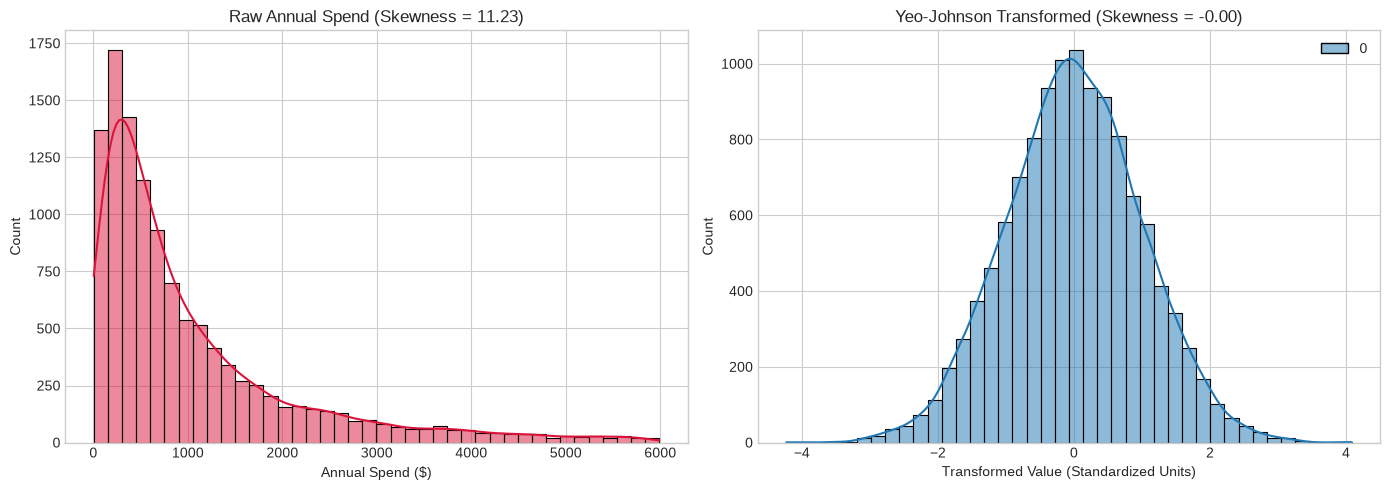

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw distribution (truncated for visualization)
sns.histplot(spend_raw[spend_raw < 6000], kde=True, ax=axes[0], color="crimson", bins=40)
axes[0].set_title(f"Raw Annual Spend (Skewness = {skew_raw:.2f})")
axes[0].set_xlabel("Annual Spend ($)")

# Transformed distribution
sns.histplot(spend_yj, kde=True, ax=axes[1], color="royalblue", bins=40)
axes[1].set_title(f"Yeo-Johnson Transformed (Skewness = {skew_yj:.2f})")
axes[1].set_xlabel("Transformed Value (Standardized Units)")

plt.tight_layout()
plt.show()

### 7.2 Visualizing Cyclical Feature Encoding

Plotting $\sin(\text{hour})$ vs. $\cos(\text{hour})$ reveals the preserved circular topology: hour 23 and hour 0 are contiguous neighbors on the circumference.

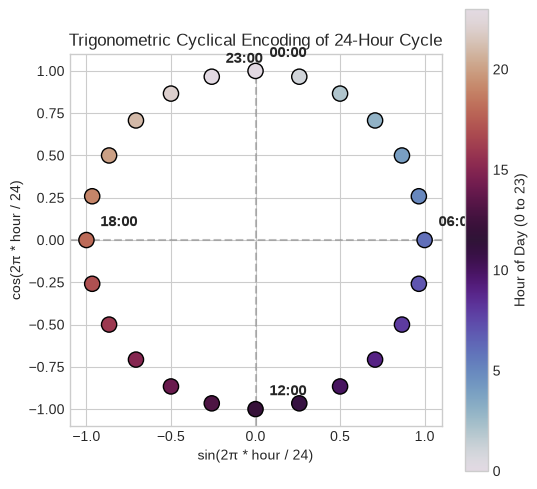

In [9]:
hours = np.arange(24)
sin_h = np.sin(2 * np.pi * hours / 24.0)
cos_h = np.cos(2 * np.pi * hours / 24.0)

plt.figure(figsize=(6, 6))
plt.scatter(sin_h, cos_h, c=hours, cmap="twilight", s=120, edgecolors="black", zorder=3)
plt.colorbar(label="Hour of Day (0 to 23)")

for h in [0, 6, 12, 18, 23]:
    plt.annotate(
        f"{h:02d}:00",
        (sin_h[h], cos_h[h]),
        textcoords="offset points",
        xytext=(10, 10),
        weight="bold",
        fontsize=11
    )

plt.axhline(0, color="gray", linestyle="--", alpha=0.5)
plt.axvline(0, color="gray", linestyle="--", alpha=0.5)
plt.title("Trigonometric Cyclical Encoding of 24-Hour Cycle")
plt.xlabel("sin(2π * hour / 24)")
plt.ylabel("cos(2π * hour / 24)")
plt.gca().set_aspect("equal")
plt.show()

### 7.3 Quantifying Downstream Model Improvement

We benchmark Logistic Regression across four stages:
1. **Raw Baseline**: Simple median imputation + standard scaling on numerical features only.
2. **+ Categorical Encodings**: Adding Target Encodings.
3. **+ Full Feature Engineering**: Adding cyclical features and interaction ratios.
4. **+ Feature Selection**: Pruning uninformative and noise features using top Mutual Information features.

In [10]:
X_test = test_engineered.drop(columns=["high_value_customer"])
y_test = test_engineered["high_value_customer"]

# Selected top features from Mutual Info (excluding pure noise)
selected_cols = mi_series.head(7).index.tolist()

models = {
    "1. Raw Baseline (Numerics Only)": (train_raw[num_cols].fillna(0), test_raw[num_cols].fillna(0)),
    "2. + Target Encoding": (
        train_engineered[num_cols + ["te_merchant_cat", "te_customer_city"]],
        test_engineered[num_cols + ["te_merchant_cat", "te_customer_city"]]
    ),
    "3. + Full Feature Engineering": (X_train, X_test),
    "4. + Feature Selection (Top 7 MI Features)": (X_train[selected_cols], X_test[selected_cols])
}

benchmark_results = []
for name, (X_tr, X_te) in models.items():
    sc = StandardScaler()
    X_tr_s = sc.fit_transform(X_tr)
    X_te_s = sc.transform(X_te)
    
    clf = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)
    clf.fit(X_tr_s, y_train)
    
    test_auc = roc_auc_score(y_test, clf.predict_proba(X_te_s)[:, 1])
    test_acc = accuracy_score(y_test, clf.predict(X_te_s))
    
    benchmark_results.append({
        "Pipeline Stage": name,
        "Features Used": X_tr.shape[1],
        "Test ROC-AUC": test_auc,
        "Test Accuracy": test_acc
    })

pd.DataFrame(benchmark_results).set_index("Pipeline Stage")

,Features Used,Test ROC-AUC,Test Accuracy
Pipeline Stage,,,
1. Raw Baseline (Numerics Only),5,0.8452,0.7623
2. + Target Encoding,7,0.8562,0.7730
3. + Full Feature Engineering,13,0.8569,0.7723
4. + Feature Selection (Top 7 MI Features),7,0.8460,0.7667


## 8. Guided Exercises

### Exercise 1: High-Cardinality Frequency/Count Encoding Transformer

In frequency encoding, each categorical level is replaced by its normalized frequency (probability of occurrence) in the training set:

$$f(c) = \frac{\text{count}(c)}{N}$$

Implement a custom transformer `FrequencyEncoder` inheriting from `BaseEstimator` and `TransformerMixin` that handles unseen test categories by assigning a frequency of `0.0`.

In [11]:
# --- YOUR CODE HERE ---
class FrequencyEncoder(BaseEstimator, TransformerMixin):
    """Encodes categorical columns by their empirical relative frequencies in the training set."""
    
    def __init__(self):
        pass
        
    def fit(self, X: Any, y: Any = None) -> "FrequencyEncoder":
        X_df = pd.DataFrame(X)
        self.frequencies_: Dict[Any, Dict[Any, float]] = {}
        n_samples = len(X_df)
        
        for col in X_df.columns:
            freq_map = (X_df[col].value_counts() / n_samples).to_dict()
            self.frequencies_[col] = freq_map
            
        return self
        
    def transform(self, X: Any) -> np.ndarray:
        X_df = pd.DataFrame(X)
        X_out = pd.DataFrame(index=X_df.index)
        
        for col in X_df.columns:
            freq_map = self.frequencies_[col]
            X_out[f"freq_{col}"] = X_df[col].map(freq_map).fillna(0.0)
            
        return X_out.to_numpy(dtype=float)

# Test FrequencyEncoder on merchant_cat and customer_city
freq_enc = FrequencyEncoder()
sample_cats = train_raw[["merchant_cat", "customer_city"]].fillna("Missing")
freq_result = freq_enc.fit_transform(sample_cats)

print(f"Frequency encoded shape: {freq_result.shape}")
print("Sample frequency encodings (first 5 rows):")
print(freq_result[:5])

Frequency encoded shape: (9000, 2)
Sample frequency encodings (first 5 rows):
[[0.05544444 0.06511111]
 [0.11144444 0.11955556]
 [0.06888889 0.10544444]
 [0.24211111 0.13644444]
 [0.14555556 0.00488889]]


### Exercise 2: Outlier-Robust Normalization with `RobustScaler` and `QuantileTransformer`

Generate a synthetic dataset with Cauchy-distributed fat-tailed extreme outliers ($X \sim \text{Cauchy}(0, 1)$). Compare the interquartile range and mean of the transformed data when using `StandardScaler` vs. `RobustScaler` vs. `QuantileTransformer`.

In [12]:
# --- YOUR CODE HERE ---
rng = np.random.default_rng(RANDOM_SEED)
fat_tailed_data = rng.standard_cauchy(size=(2000, 1))

ss = StandardScaler()
rs = RobustScaler()
qt = QuantileTransformer(output_distribution="normal", random_state=RANDOM_SEED)

scaled_ss = ss.fit_transform(fat_tailed_data)
scaled_rs = rs.fit_transform(fat_tailed_data)
scaled_qt = qt.fit_transform(fat_tailed_data)

def summary_stats(arr: np.ndarray, name: str) -> Dict[str, Any]:
    return {
        "Scaler": name,
        "Mean": np.mean(arr),
        "Median": np.median(arr),
        "IQR (Q75 - Q25)": np.percentile(arr, 75) - np.percentile(arr, 25),
        "Max": np.max(arr),
        "Min": np.min(arr)
    }

pd.DataFrame([
    summary_stats(fat_tailed_data, "Original Cauchy (Extreme Outliers)"),
    summary_stats(scaled_ss, "StandardScaler (Distorted by Outliers)"),
    summary_stats(scaled_rs, "RobustScaler (Stable IQR = 1.0)"),
    summary_stats(scaled_qt, "QuantileTransformer (Normal Gaussian)")
]).set_index("Scaler")

,Mean,Median,IQR (Q75 - Q25),Max,Min
Scaler,,,,,
Original Cauchy (Extreme Outliers),3.7427e-02,0.0467,1.9590,629.8543,-847.1631
StandardScaler (Distorted by Outliers),0.0000e+00,0.0003,0.0629,20.2283,-27.2102
RobustScaler (Stable IQR = 1.0),-4.7297e-03,0.0000,1.0000,321.4912,-432.4663
QuantileTransformer (Normal Gaussian),1.2532e-05,-0.0005,1.3484,5.1993,-5.1993


## 9. Challenge Problems

### Challenge 1: Implementing a Boruta-Style Shadow Feature Selection Algorithm

The **Boruta** algorithm provides an all-relevant feature selection mechanism by comparing real feature importances against randomly permuted "shadow" features:
1. For every real feature $X_j$, generate a shadow duplicate $X_j^{\text{shadow}}$ by shuffling $X_j$ randomly to destroy correlation with $y$.
2. Train a `RandomForestClassifier` on the combined $[X \Vert X_{\text{shadow}}]$ matrix.
3. Find the maximum importance achieved across all shadow features: $Z_{\max} = \max(\text{importance}_{\text{shadow}})$.
4. Retain only features whose importance exceeds $Z_{\max}$.

Implement this function from scratch and test it on our engineered e-commerce dataset.

In [13]:
# --- YOUR CODE HERE ---
def boruta_shadow_feature_selection(
    X: pd.DataFrame, 
    y: pd.Series, 
    n_estimators: int = 100, 
    random_state: int = RANDOM_SEED
) -> Tuple[List[str], pd.DataFrame]:
    """Selects all features that outperform the best randomized shadow feature."""
    rng = np.random.default_rng(random_state)
    
    # 1. Create shadow features by shuffling columns independently
    X_shadow = X.copy()
    for col in X_shadow.columns:
        X_shadow[f"shadow_{col}"] = rng.permutation(X[col].to_numpy())
        
    # 2. Fit Random Forest on combined dataset
    rf = RandomForestClassifier(n_estimators=n_estimators, max_depth=8, random_state=random_state, n_jobs=-1)
    rf.fit(X_shadow, y)
    
    # 3. Compute shadow threshold
    real_cols = X.columns.tolist()
    shadow_cols = [f"shadow_{c}" for c in real_cols]
    
    importances = pd.Series(rf.feature_importances_, index=X_shadow.columns)
    max_shadow_importance = importances[shadow_cols].max()
    
    # 4. Compare real features to max shadow importance
    real_importances = importances[real_cols].sort_values(ascending=False)
    confirmed_features = real_importances[real_importances > max_shadow_importance].index.tolist()
    
    comparison_df = pd.DataFrame({
        "Real Feature Importance": real_importances,
        "Outperforms Shadow Threshold": real_importances > max_shadow_importance
    })
    
    print(f"Maximum Shadow Feature Importance: {max_shadow_importance:.5f}")
    print(f"Confirmed Features Count:          {len(confirmed_features)} / {len(real_cols)}")
    
    return confirmed_features, comparison_df

confirmed_feats, boruta_df = boruta_shadow_feature_selection(X_train, y_train)
boruta_df

Maximum Shadow Feature Importance: 0.01108
Confirmed Features Count:          9 / 13


,Real Feature Importance,Outperforms Shadow Threshold
annual_spend,0.2919,True
spend_per_page,0.2023,True
cart_value,0.1208,True
cart_to_spend_ratio,0.1045,True
session_duration_min,0.0477,True
return_rate,0.0320,True
pages_viewed,0.0255,True
te_merchant_cat,0.0174,True
noise_gaussian,0.0118,True
noise_uniform,0.0109,False


### Challenge 2: Grouped Aggregation Features Without Data Leakage

In transactional ML, a powerful predictor is a customer's deviation from their peer group (e.g. *"Is this customer spending more than average for their city?"*):

$$\Delta_i = \text{spend}_i - \mathbb{E}[\text{spend} | \text{city} = c_i]$$

Implement a custom transformer `GroupedAggregationTransformer` inheriting `BaseEstimator` and `TransformerMixin` that:
1. Learns group-level mean and standard deviation from training folds during `fit`.
2. Computes the group Z-score ($z = \frac{x - \mu_{\text{group}}}{\sigma_{\text{group}}}$) during `transform`.
3. Handles unseen groups in the test set by falling back to the global dataset mean and standard deviation.

In [14]:
# --- YOUR CODE HERE ---
class GroupedAggregationTransformer(BaseEstimator, TransformerMixin):
    """Calculates group-relative deviations (Z-score within group) without data leakage."""
    
    def __init__(self, group_col: str, target_numeric_col: str):
        self.group_col = group_col
        self.target_numeric_col = target_numeric_col
        
    def fit(self, X: Any, y: Any = None) -> "GroupedAggregationTransformer":
        X_df = pd.DataFrame(X)
        self.global_mean_ = X_df[self.target_numeric_col].mean()
        self.global_std_ = X_df[self.target_numeric_col].std()
        if self.global_std_ == 0.0 or np.isnan(self.global_std_):
            self.global_std_ = 1.0
            
        grouped = X_df.groupby(self.group_col)[self.target_numeric_col]
        self.group_means_ = grouped.mean().to_dict()
        self.group_stds_ = grouped.std().fillna(self.global_std_).to_dict()
        
        return self
        
    def transform(self, X: Any) -> np.ndarray:
        X_df = pd.DataFrame(X)
        means = X_df[self.group_col].map(self.group_means_).fillna(self.global_mean_)
        stds = X_df[self.group_col].map(self.group_stds_).fillna(self.global_std_)
        stds = np.where(stds == 0.0, self.global_std_, stds)
        
        z_scores = (X_df[self.target_numeric_col] - means) / stds
        return z_scores.to_numpy(dtype=float).reshape(-1, 1)

# Test GroupedAggregationTransformer
group_transformer = GroupedAggregationTransformer(group_col="customer_city", target_numeric_col="annual_spend")
city_spend_z = group_transformer.fit_transform(train_raw)

print(f"Grouped aggregation Z-scores shape: {city_spend_z.shape}")
print(f"First 5 customer city-relative Z-scores:\n{city_spend_z[:5].ravel()}")

Grouped aggregation Z-scores shape: (9000, 1)
First 5 customer city-relative Z-scores:
[ 0.08364429 -0.27738963 -0.12657907  0.42272255 -0.01533854]


## 10. Further Reading

- **Kuhn, M. & Johnson, K. (2019)**: *Feature Engineering and Selection: A Practical Approach for Predictive Models*. Chapman & Hall/CRC Data Science Series.
- **Micci-Barreca, D. (2001)**: *A Preprocessing Scheme for High-Cardinality Categorical Attributes in Classification and Prediction Problems*. ACM SIGKDD Explorations, 3(1), 27-32.
- **Yeo, I. K. & Johnson, R. A. (2000)**: *A New Family of Power Transformations to Improve Normality or Symmetry*. Biometrika, 87(4), 954-959.
- **Kursa, M. B. & Rudnicki, W. R. (2010)**: *Feature Selection with the Boruta Package*. Journal of Statistical Software, 36(11).
- **scikit-learn Documentation**:
  - [Preprocessing Data Guide](https://scikit-learn.org/stable/modules/preprocessing.html)
  - [TargetEncoder with Cross-Fitting](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.TargetEncoder.html)
  - [Feature Selection Algorithms](https://scikit-learn.org/stable/modules/feature_selection.html)